In [1]:
import cPickle as pickle
import os

import numpy as np
import matplotlib.pyplot as plt
import quantities as pq
import scipy.sparse as sparse
from scipy.io import wavfile
from IPython.display import Audio, display

import soundsig
from soundsig.sound import spectrogram, plot_spectrogram
from soundsig.signal import lowpass_filter, highpass_filter
import config
from segment_analysis import MultiSegment
from adaptivekde import ssvkernel

from spikes.plotting import plot_spikes_with_timeseries
from spikes.plotting.segment_view import PlaybacksManager, SegmentViewer, TrialsViewer
from spikes.sorting.preprocess import collect_waveforms
from spikes.plotting import raster
from spikes.utils import bin_spikes

#from songephys.autodetect import get_symmetric_spect_corr

%matplotlib inline
%load_ext autoreload
%autoreload 2

In [2]:
BIRD_NAME = "LbY6074"
BIRD = "LbY6074__161215_145633"

In [3]:
DATADIR = config.DATADIR
data_path = os.path.join(DATADIR, "birds", BIRD_NAME, BIRD, "spikes", "{}-sorted.pkl".format(BIRD))

In [4]:
with open(data_path, "rb") as datafile:
    block = pickle.load(datafile)
block.create_relationship(recursive=True, force=True, append=True)

In [5]:
# segments with song, numbers of bouts
align4 = [0, 7, 16, 80]
align3 = [1, 9, 11, 19, 21, 68, 69, 71, 73, 74, 82, 95, 97, 98]
align2 = [2, 3, 4, 5, 8, 10, 12, 13, 17, 18, 20, 22, 67, 72, 85, 92, 93, 94, 99]

units_of_interest = [5, 11]

In [6]:
print len(align4), len(align3)

4 14


In [7]:
multiseg = MultiSegment(np.array(block.segments)[align3 + align4])
print multiseg

MultiSegment with 18 Segments, 13 Units, t_start=-0.0s, t_stop=4.9692s
{'vocalization_type': 'unknown', 'sound_type': 'live', 'vocalizer': 'unknown', 'playback_file': None}


## Response to tutor song

Example tutor song shown

* Spikes convolved with gaussian with width std=0.4ms

* N=19 songs


In [10]:
# get onset times

plt.clf()
#plot_spectrogram(t[t1:t2], f, basesig)
onset_times_tutor = []
for sid in align3 + align4:
    mmm = 0
    bleh = np.mean(abs(SegmentViewer(block.segments[sid]).spectrogram(source=1)[2])**2, axis=0)
    for i, x in enumerate(bleh[440:1000]):
        if x > 1.6e-7:
            mmm = i
            break
#     print sid, (440 + mmm)/1000.0
    onset_times_tutor.append((440 + mmm)/1000.0)
#     plt.figure()
#     plt.plot(bleh[440:1000])
#     plt.hlines([1.6e-7], 0, 400)
#     plt.vlines([mmm], 0, 1.6e-7)
#     plt.show()

In [11]:
multiseg.set_offsets(onset_times_tutor)
print multiseg

MultiSegment with 18 Segments, 13 Units, t_start=-0.855s, t_stop=4.1302s
{'vocalization_type': 'unknown', 'sound_type': 'live', 'vocalizer': 'unknown', 'playback_file': None}


TypeError: gaussian_convolver() takes at least 1 argument (0 given)

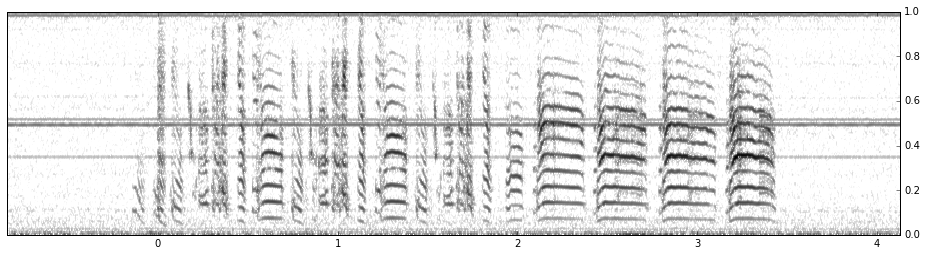

In [13]:
plt.clf()
trials_viewer = TrialsViewer(multiseg)
# seg_viewer = trials_viewer.segment_viewers[0]

for seg_idx, seg_viewer in enumerate(trials_viewer.segment_viewers[:3]):
    for fig_idx, unit in enumerate(units_of_interest):    
        fig, ax = plt.subplots(figsize=(16, 4))
        
        # set t start to align with the reset zero point!
        seg_viewer.plot_spectrogram(ax=ax, source=1, zero_point=onset_times_tutor[seg_idx])
        plt.ylabel("")
        plt.xlabel("")
        plt.yticks([])

        ax = ax.twinx()
        trials_viewer.plot_psth(unit, ax=ax, color="Blue", alpha=0.1)#, conv_width=5.0)
        plt.yticks([0, 0.1, 0.2])
        plt.ylabel("Hz")
        plt.xlim(-0.5, 2.0)
        plt.ylim(-.01, 0.2)
#         plt.vlines(onset_times_tutor[seg_idx], *plt.ylim())
        plt.vlines(0.0, *plt.ylim())
        # plt.tight_layout()
    plt.show()

In [28]:
plt.clf()
trials_viewer = TrialsViewer(np.array(block.segments)[align3 + align4])
seg_viewer = trials_viewer.segment_viewers[0]

for fig_idx, unit in enumerate(units_of_interest):    
    fig, ax = plt.subplots(figsize=(16, 4))
    seg_viewer.plot_spectrogram(ax=ax, source=0, t_start=0)
    plt.ylabel("")
    plt.xlabel("")
    plt.yticks([])

    ax = ax.twinx()
    trials_viewer.plot_psth(unit, ax=ax, color="Blue", alpha=0.1, t_start=0)#, conv_width=5.0)
    plt.yticks([0, 0.1, 0.2])
    plt.ylabel("Hz")
    plt.xlim(0, 3.0)
    plt.ylim(-.01, 0.2)

    # plt.tight_layout()
plt.show()



AttributeError: 'numpy.ndarray' object has no attribute 'segments'

In [ ]:
    ssvkernel

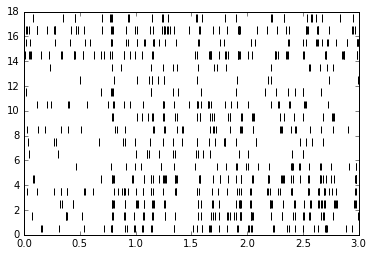

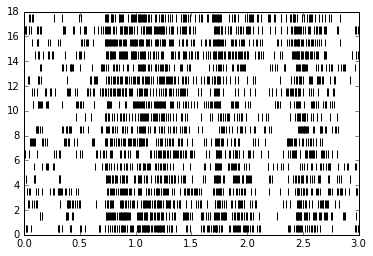

In [361]:
for unit in units_of_interest:
    raster.plot(
        trials_viewer.spike_times(unit),
        min_time=0.0,
        max_time=3.0
    )
    plt.show()

In [54]:
alignBOS = [14, 15, 23, 24, 26, 27, 28, 29, 30, 32, 34, 35, 36, 37, 38, 39, 41, 42, 43, 44, 45, 47, 48, 49, 55]
alignBOS = [14, 15, 23, 24, 26, 28, 29, 30, 32, 34, 35, 36, 37, 38, 39, 41, 42, 43, 44, 45, 47, 48, 49, 55]
print len(alignBOS)

24


In [329]:
# plt.clf()
# for i, seg in enumerate(np.array(block.segments)[alignBOS]):
#     if seg.annotations["sound_type"] == "playback":
#         continue
#     seg_viewer = SegmentViewer(seg)
#     trials_viewer = TrialsViewer([seg])
    
#     # TODO: view spectrogram of playback wav file too
#     plt.figure(figsize=(5, 1.5))
#     seg_viewer.plot_spectrogram(source=0)
#     plt.xlim(0.2, 1.4)
#     plt.ylabel("")
#     plt.xlabel("")
#     plt.yticks([])
#     plt.title(alignBOS[i])

# #     plt.tight_layout()
#     plt.show()

In [362]:
plt.clf()
#plot_spectrogram(t[t1:t2], f, basesig)
onset_times = []
for sid in alignBOS:
    bleh = np.mean(abs(SegmentViewer(block.segments[sid]).spectrogram(source=1)[2])**2, axis=0)
    for i, x in enumerate(bleh[440:1000]):
        if x > 1e-7:
            mmm = i
            break
    print sid, (440 + mmm)/1000.0
    onset_times.append((440 + mmm)/1000.0)
#    plt.figure()
#    plt.plot(bleh[440:1000])
#    plt.hlines([1e-7], 0, 400)
#    plt.vlines([mmm], 0, 1e-7)
#    plt.show()

14 0.679
15 0.696
23 0.693
24 0.694
26 0.665
28 0.568
29 0.668
30 0.691
32 0.683
34 0.672
35 0.65
36 0.68
37 0.682
38 0.682
39 0.674
41 0.68
42 0.655
43 0.656
44 0.66
45 0.68
47 0.676
48 0.678
49 0.691
55 0.669


## Response to BOS

Onsets aligned, lots of variability in syllable timing though

* Spikes convolved with gaussian with width std=0.4ms

* N=24 songs


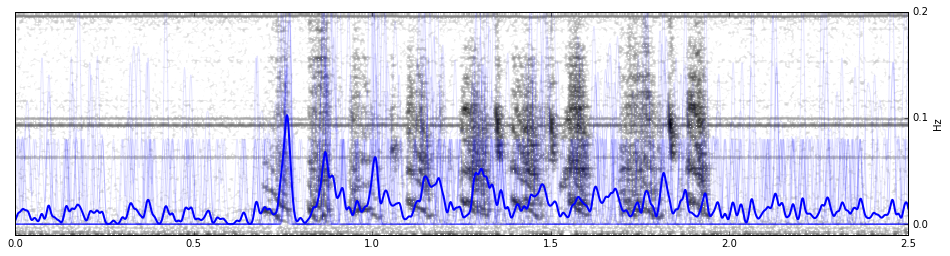

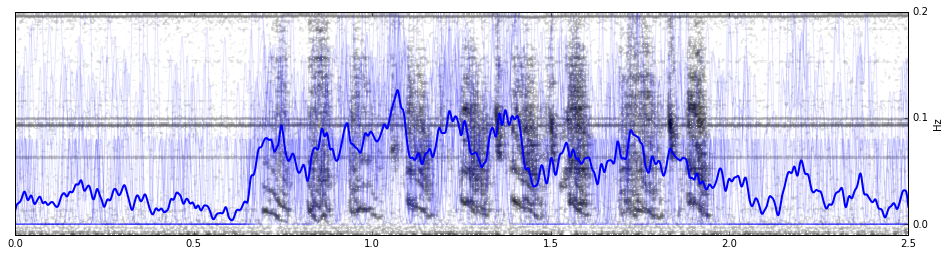

In [56]:
plt.clf()
trials_viewer = TrialsViewer(np.array(block.segments)[alignBOS], np.array(onset_times)-np.mean(onset_times))
seg_viewer = trials_viewer.segment_viewers[1]

for fig_idx, unit in enumerate(units_of_interest):    
    fig, ax = plt.subplots(figsize=(16, 4))
    seg_viewer.plot_spectrogram(ax=ax, source=1, t_start=0)
    plt.ylabel("")
    plt.xlabel("")
    plt.yticks([])

    ax = ax.twinx()
    trials_viewer.plot_psth(unit, ax=ax, color="Blue", alpha=0.1, t_start=0, conv_width = 5.0)
    plt.yticks([0, 0.1, 0.2])
    plt.ylabel("Hz")
    plt.xlim(0, 2.5)
    plt.ylim(-.01, 0.2)

    # plt.tight_layout()
plt.show()

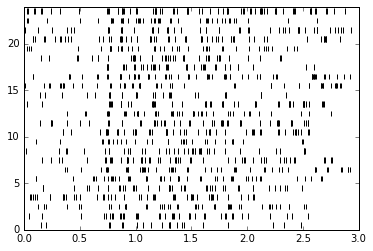

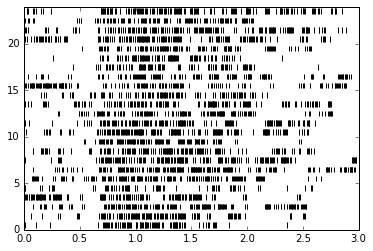

In [57]:
for unit in units_of_interest:
    raster.plot(
        trials_viewer.spike_times(unit),
        min_time=0.0,
        max_time=3.0
    )
    plt.show()

## Comparison to unaligned

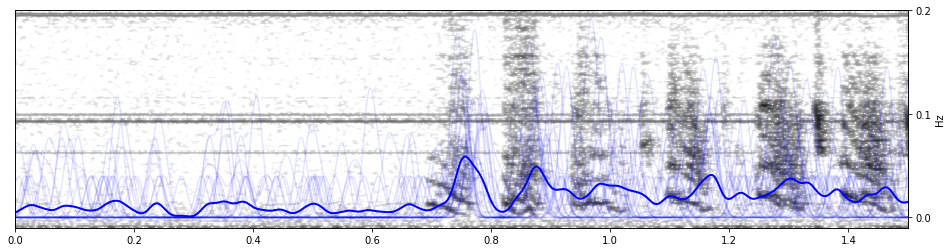

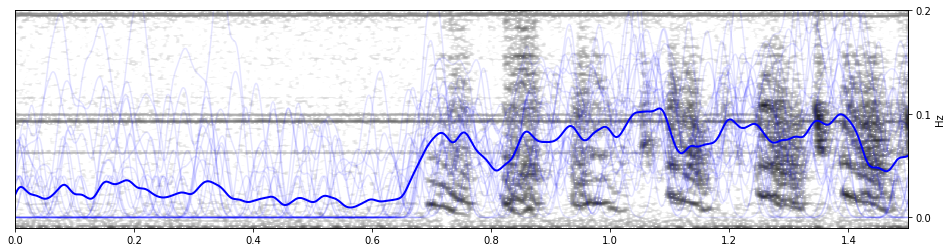

In [266]:
plt.clf()
trials_viewer = TrialsViewer(np.array(block.segments)[alignBOS])
seg_viewer = trials_viewer.segment_viewers[1]

for fig_idx, unit in enumerate(units_of_interest):    
    fig, ax = plt.subplots(figsize=(16, 4))
    seg_viewer.plot_spectrogram(ax=ax, source=1, t_start=0)
    plt.ylabel("")
    plt.xlabel("")
    plt.yticks([])

    ax = ax.twinx()
    trials_viewer.plot_psth(unit, ax=ax, color="Blue", alpha=0.1, t_start=0)
    plt.yticks([0, 0.1, 0.2])
    plt.ylabel("Hz")
    plt.xlim(0, 1.5)
    plt.ylim(-.01, 0.2)

    # plt.tight_layout()
plt.show()

# Crystallized Song Spectrograms

In [180]:
wav_dir = "/auto/tdrive/billewood/intan data/LbY6074/crystallized song/"
wav_files = os.listdir(wav_dir)
wav_files = [file for file in wav_files if ".wav" in file]
wav_files[0]

'LBlYel923__January_06_2017_36591610.wav'

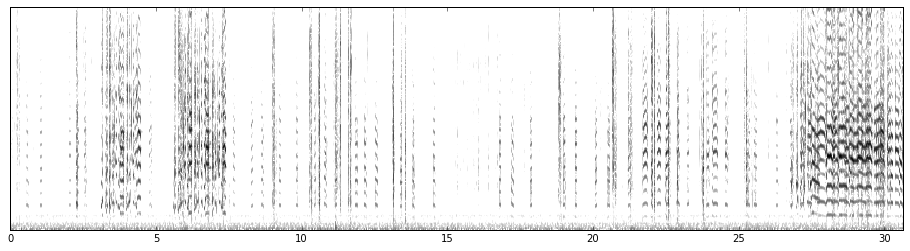

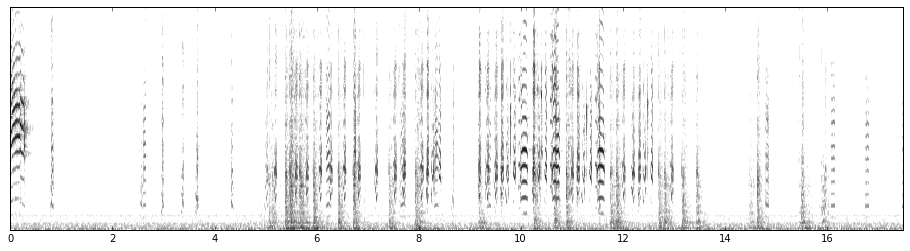

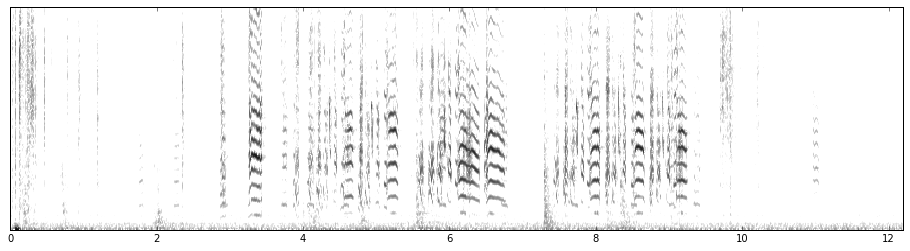

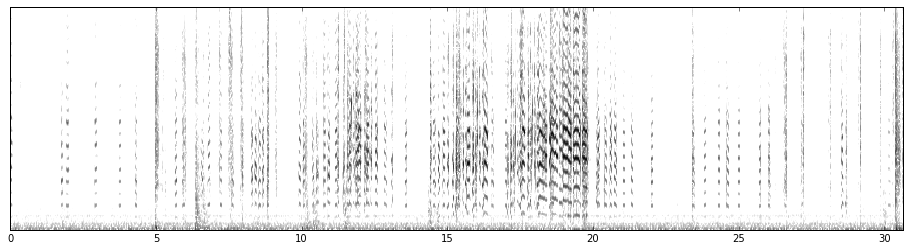

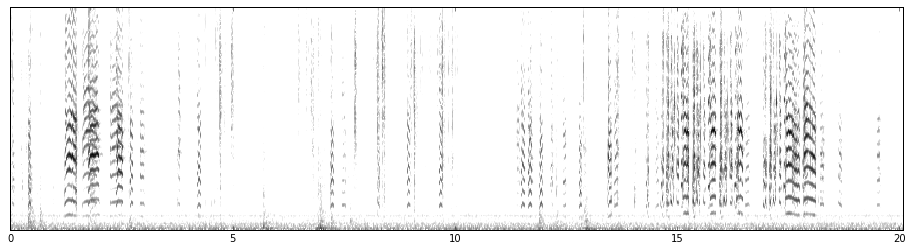

...

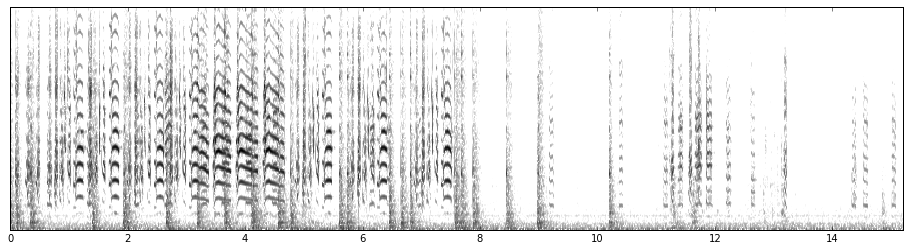

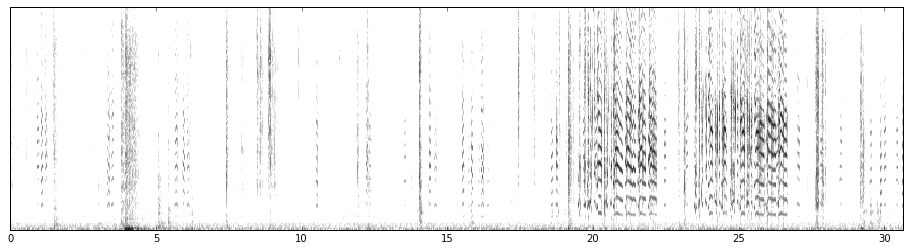

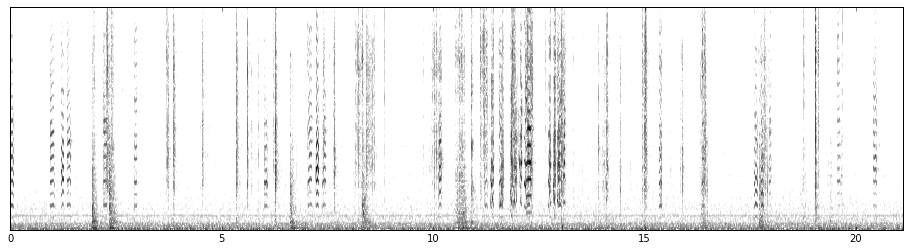

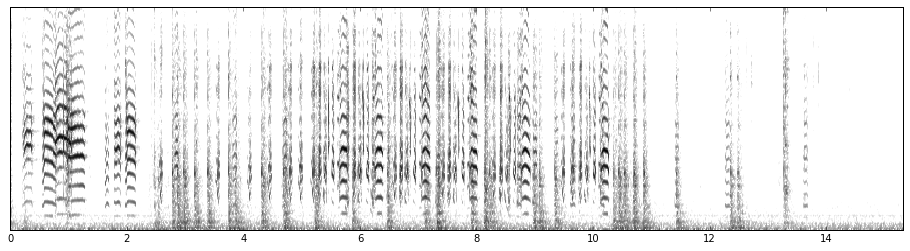

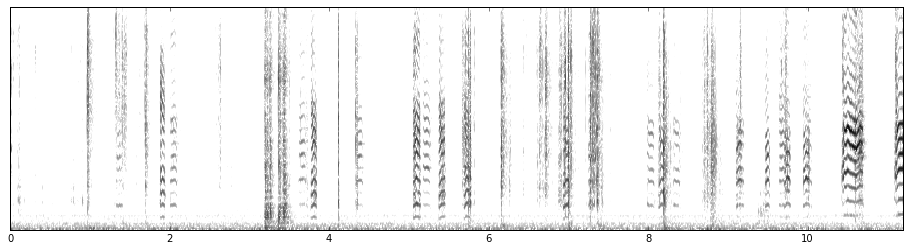

In [177]:
#Scan through crystallized songs
wav_dir = "/auto/tdrive/billewood/intan data/LbY6074/crystallized song/"
wav_files = os.listdir(wav_dir)
for file in wav_files: 
    sr, crystallized_song = wavfile.read(os.path.join(wav_dir,file))
    t_spec, f_spec, spec, rms = spectrogram(
        crystallized_song - np.mean(crystallized_song),
        sr,
        1000.0,
        50.0,
        min_freq=0,
        max_freq=10000,
        nstd=6)
    t_spec = t_spec - t_spec[0]

    fig, ax = plt.subplots(figsize=(16, 4))
    plot_spectrogram(t_spec, f_spec, spec, colormap="gray_r", ax=ax, colorbar=False)
    plt.ylabel("")
    plt.xlabel("")
    plt.yticks([])

plt.xlim(0, 11.2)
plt.show()

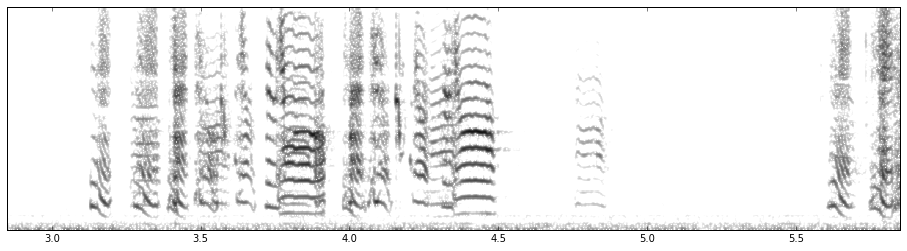

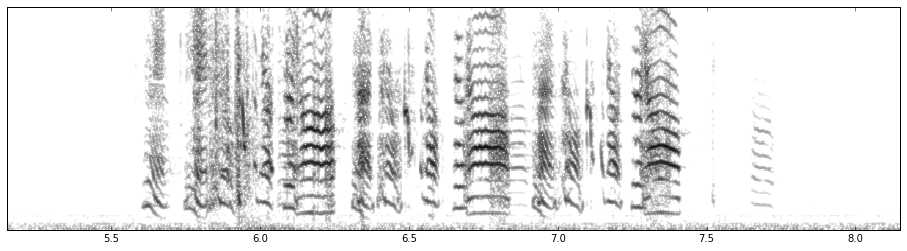

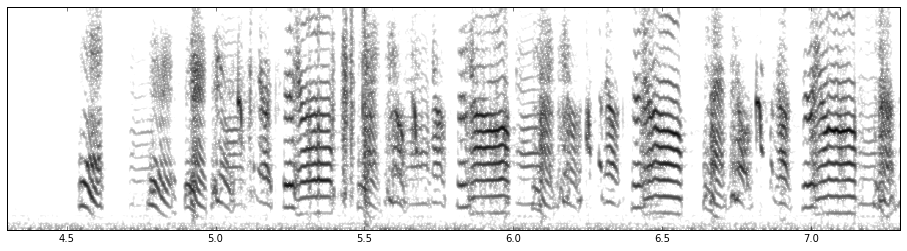

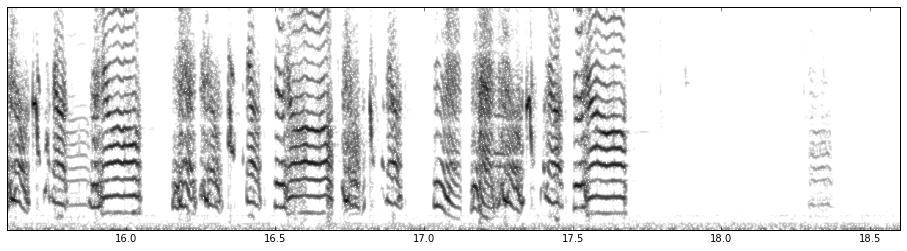

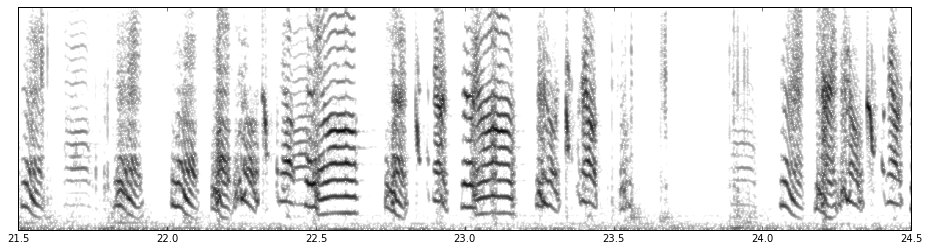

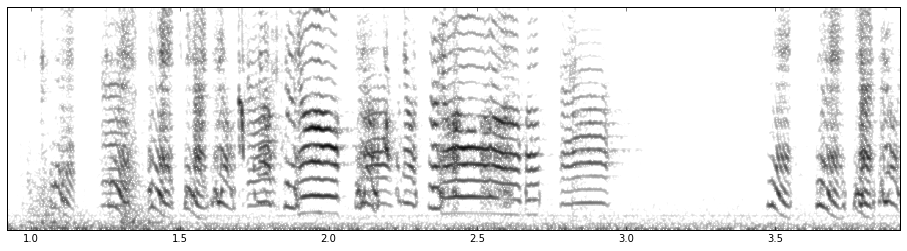

In [266]:
good_files = [0, 0, 5, 5, 5, 8]
start_times = [2.85, 5.15, 4.3, 15.6, 21.5, 0.92]
for i, index in enumerate(good_files):
    file = wav_files[index]
    sr, crystallized_song = wavfile.read(os.path.join(wav_dir,file))
    t_spec, f_spec, spec, rms = spectrogram(
        crystallized_song - np.mean(crystallized_song),
        sr,
        1000.0,
        50.0,
        min_freq=0,
        max_freq=10000,
        nstd=6)
    t_spec = t_spec - t_spec[0]

    fig, ax = plt.subplots(figsize=(16, 4))
    plot_spectrogram(t_spec, f_spec, spec, colormap="gray_r", ax=ax, colorbar=False)
    plt.ylabel("")
    plt.xlabel("")
    plt.yticks([])

    plt.xlim(start_times[i], start_times[i]+3)
plt.show()

## Plot all the spectrograms aligned

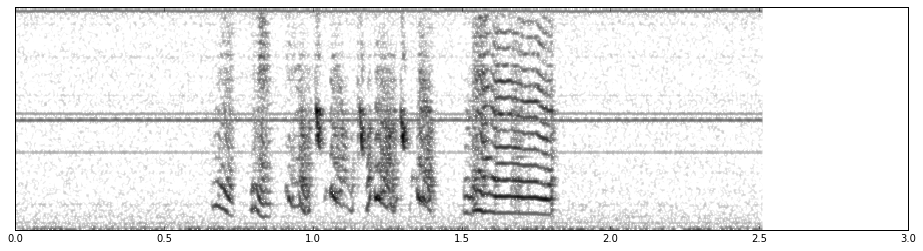

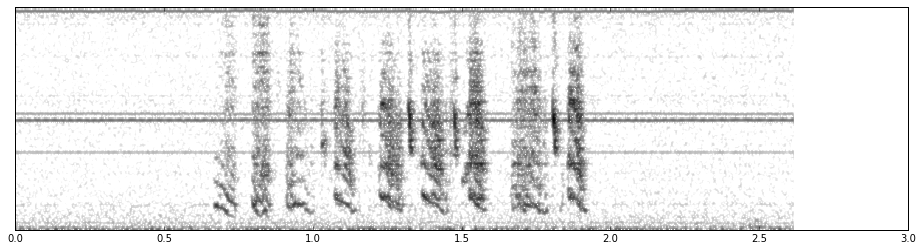

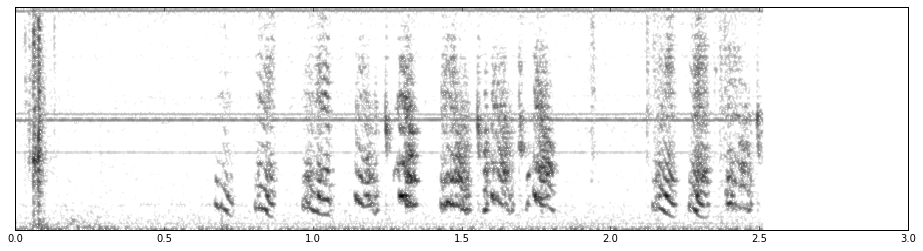

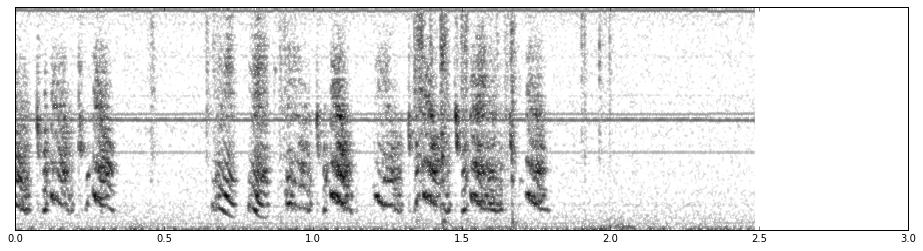

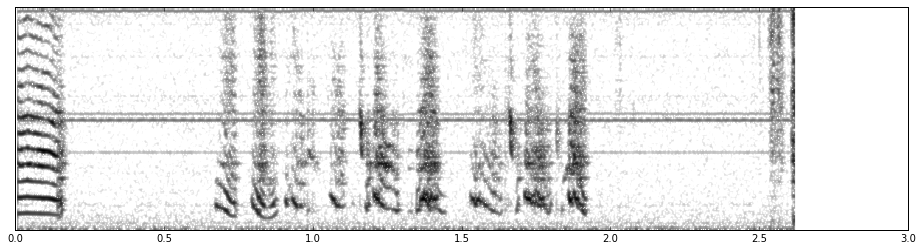

...

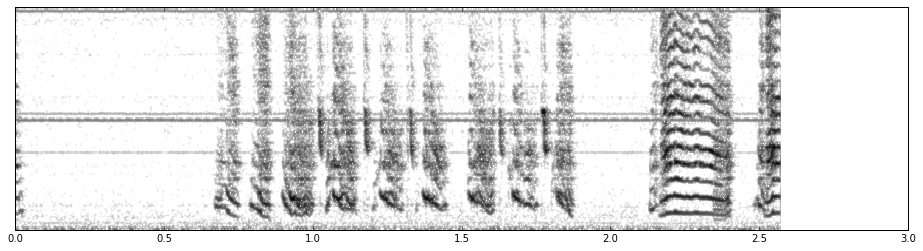

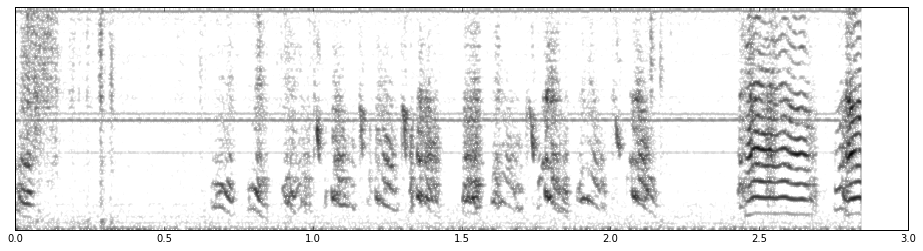

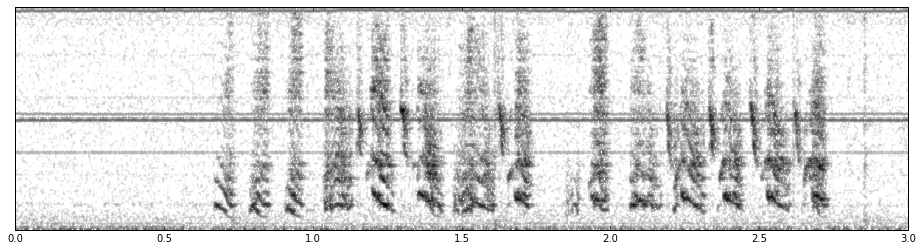

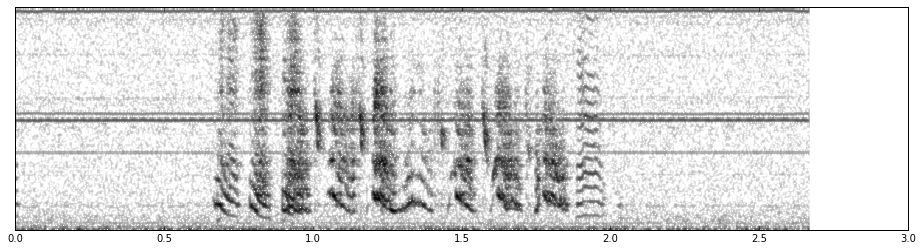

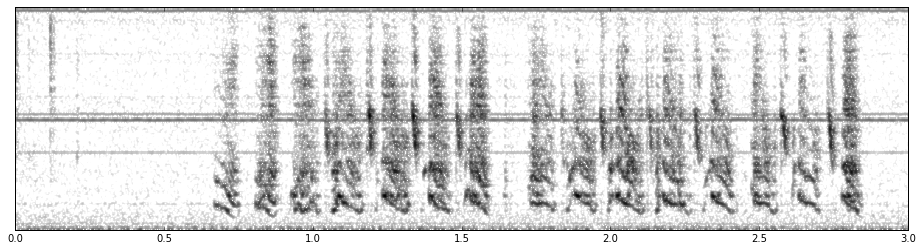

In [150]:
shifts = np.array(onset_times)-np.mean(onset_times)
plt.clf()
trials_viewer = TrialsViewer(np.array(block.segments)[alignBOS])
for i, seg_viewer in enumerate(trials_viewer.segment_viewers):
    fig, ax = plt.subplots(figsize=(16, 4))
    seg_viewer.plot_spectrogram(ax=ax, source=1, t_start=-shifts[i])
    plt.ylabel("")
    plt.xlabel("")
    plt.xlim(0, 3.0) # this is crucial to making the plots aligned
    plt.yticks([])

plt.show()
#trials_viewer.segment_viewers.seg_viewer.plot_spectrogram(ax=ax, source=1, t_start=0),


## align BOS by crossco on spectrogram of a motif

In [368]:
seg = block.segments[alignBOS[0]]
bos = np.asarray(seg.analogsignals[0])[16000:26500,0]
Fs = np.int(np.round(seg.analogsignals[0].sampling_rate))
bos = highpass_filter(bos, Fs, 100)
#plt.plot(bos)


In [373]:
silence = np.asarray(seg.analogsignals[0])[14000:16000,0]

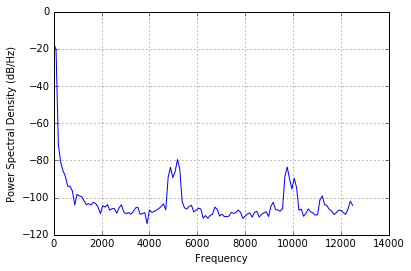

In [377]:
plt.psd(silence, Fs = Fs);

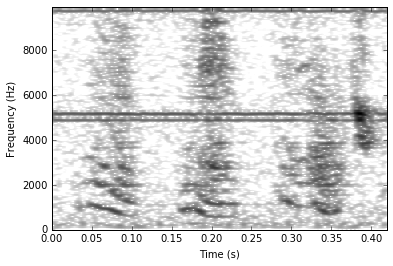

In [354]:
bos_t_spec, bos_f_spec, bos_spec, bos_rms = spectrogram(
            bos - np.mean(bos),
            Fs,
            1000.0,
            50.0,
            min_freq=0,
            max_freq=10000,
            nstd=6)
#bos_spec = zscore(bos_spec)
fig, ax = plt.subplots()
plot_spectrogram(bos_t_spec, bos_f_spec, bos_spec, colormap="gray_r", ax=ax, colorbar=False)


In [356]:
amps = list()
corrs = list()
for i, sid in enumerate(alignBOS):
    seg = block.segments[sid]
    sound = highpass_filter(np.asarray(seg.analogsignals[0])[:,0], Fs, 100)
    t_spec, f_spec, spec, rms = spectrogram(
            sound - np.mean(sound),
            Fs,
            1000.0,
            50.0,
            min_freq=0,
            max_freq=10000,
            nstd=6)
    #spec = zscore(spec)
    spect_corr, amp_corr = get_symmetric_spect_corr(spec, bos_spec)
    corrs.append(spect_corr)
    amps.append(amp_corr)

/auto/fhome/billewood/.local/lib/python2.7/site-packages/ipykernel/__main__.py:45: ComplexWarning: Casting complex values to real discards the imaginary part
/auto/fhome/billewood/.local/lib/python2.7/site-packages/ipykernel/__main__.py:49: ComplexWarning: Casting complex values to real discards the imaginary part


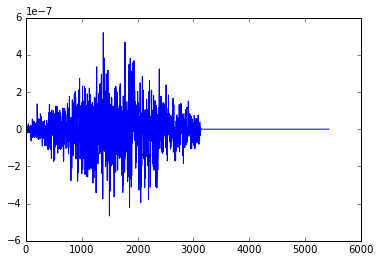

In [367]:
plt.plot(amps[5])


In [ ]:
for sid in alignBOS:
    bleh = np.mean(abs(SegmentViewer(block.segments[sid]).spectrogram(source=1)[2])**2, axis=0)
#   bleh = np.mean(abs(SegmentViewer(block.segments[sid]).spectrogram(source=1)[2])**2, axis=0)

    for i, x in enumerate(bleh[440:1000]):
        if x > 1e-7:
            mmm = i
            break
    print sid, (440 + mmm)/1000.0
    onset_times.append((440 + mmm)/1000.0)


In [ ]:
good_files = [0, 0, 5, 5, 5, 8]
start_times = [2.85, 5.15, 4.3, 15.6, 21.5, 0.92]
for i, index in enumerate(good_files):
    file = wav_files[index]
    sr, crystallized_song = wavfile.read(os.path.join(wav_dir,file))
    t_spec, f_spec, spec, rms = spectrogram(
        crystallized_song - np.mean(crystallized_song),
        sr,
        1000.0,
        50.0,
        min_freq=0,
        max_freq=10000,
        nstd=6)
    t_spec = t_spec - t_spec[0]

    fig, ax = plt.subplots(figsize=(16, 4))
    plot_spectrogram(t_spec, f_spec, spec, colormap="gray_r", ax=ax, colorbar=False)
    plt.ylabel("")
    plt.xlabel("")
    plt.yticks([])

    plt.xlim(start_times[i], start_times[i]+3)
plt.show()

In [338]:
def get_symmetric_spect_corr(sound_timefreq, templ_timefreq, fs_mic = 25000, spec_sample_rate = 1000, freq_spacing = 50, zscore = 0):
    """
        Calculate cross correlation between two spectrograms over only some frequencies, across time. Expects one wav file and
        one spectrogram and a frequency index. The spectrogram 'timefreq' should already be zscored, this function automatically zscores the sound_wav
        spectrogram.
        If you want to run it on certain frequencies, only pass those frequencies to this function.
        Returns: 
            correlation: spect_corr
              
        Arguments:
            REQUIRED:
                sound_wav (a sound pressure vector), ?????????wrong?
                template_timefreq (from lasp.sound.spectrogram, the spectrogram (a time-frequency representation)), 
                
    """   
    if zscore:
        sound_timefreq = zscore(np.abs(sound_timefreq), axis = None) 
        templ_timefreq = zscore(np.abs(templ_timefreq), axis = None) 
    templ_len = templ_timefreq.shape[0]
    # zero pad so the template and vocal period are the same length
    if sound_timefreq.shape[1] < templ_timefreq.shape[1]:
        zeropad = np.zeros((sound_timefreq.shape[0],templ_timefreq.shape[1]-sound_timefreq.shape[1]))
        sound_timefreq = np.append(sound_timefreq, zeropad, axis = 1)
    elif sound_timefreq.shape[1] > templ_timefreq.shape[1]:
        zeropad = np.zeros((templ_timefreq.shape[0],sound_timefreq.shape[1]-templ_timefreq.shape[1]))
        templ_timefreq = np.append(templ_timefreq, zeropad, axis = 1) 
    spect_corr = np.zeros(sound_timefreq.shape[1] * 2)# twice the length
    amp_corr = np.zeros(len(spect_corr))
    freq_corr = np.zeros(templ_timefreq.shape[0]) # num of frequency bins
    freq_in1 = np.zeros(templ_timefreq.shape[0])
    freq_in2 = np.zeros(templ_timefreq.shape[0])   
    # sliding time, taking the whole template with the vocalization sliding
    for t in range((templ_timefreq.shape[1]-1) * 2): #
        t = t + 1
        if t < templ_timefreq.shape[1]: # sliding time, first half of timepoints
            in1 = sound_timefreq.T[:][-t:] # take all frequencies, restricted time- transposing seems like a weird way to do thsi but it's all ive got
            in2 = templ_timefreq.T[:][0:t]
        else: # sliding time, second half of timepoints
            in1 = sound_timefreq.T[:][0:templ_timefreq.shape[1] * 2 - t]            
            in2 = templ_timefreq.T[:][-(templ_timefreq.shape[1] - t):]
        # correlate relative freq band to each other
        for freq_i in range(in1.shape[1]): 
            freq_in1 = in1.T[freq_i][:]
            freq_in2 = in2.T[freq_i][:]
            freq_corr[freq_i] = np.sum(in1.T[freq_i][:] * in2.T[freq_i][:])
        spect_corr[t] = np.sum(freq_corr)
        # the sum of power at all frequencies is ~ a smoothed amlitude waveform, and the 
        # product of all times points is the numerator of the amplitude cross-correlation
        amp_corr[t] = np.sum((np.sum(in1.T, axis = 0) * np.sum(in2.T, axis = 0)))
       # the denominator for both is the length of the template
    return (spect_corr / templ_len * templ_timefreq.shape[0]), (amp_corr / templ_len * templ_timefreq.shape[0]) # / the length of the template before zeropadding 
